In [ ]:
import logging

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.config import DATA_DIR
from src.utils.eval_helpers import lineplot_conv_events
from src.utils.logging_config import setup_logging
from src.utils.query import QueryRunner

logger = logging.getLogger(__name__)
setup_logging()

runner = QueryRunner()

# GOAL

### The purpose of this notebook is to build a correlation map between the Two Tower's score and expected conversion

### On definit les evenements qui vont nous interesser :

La requete associée aux données du bucket est disponible en fin de document.

In [2]:
PARQUET_FILE_PATH = (
    "gs://mlflow-bucket-prod/benchmark_sandbox/TT_score_conversion_logs/"
)
events = ["clicked", "faved", "booked"]  # "viewed"

### On ulilise pyarrow afin de pouvoir filtrer nos données avant de load dans un dataframe, ce qui prend un temps considerable pour des datasets de taille importante.

### Dans un premier temps, on se contente de regarder la correlation entre le score et la conversion au rang 0 (première offre dans la playlist). Cette estimation reste valable tant que l'on recommande des offres individuelles et non des playlists? On applique donc le filtre ```(ds.field("offer_reco_rank") == 0)```

In [ ]:
import pyarrow.dataset as ds
import pyarrow.fs as pafs

fs = pafs.GcsFileSystem()

path_without_protocol = PARQUET_FILE_PATH.replace("gs://", "")
dataset = ds.dataset(path_without_protocol, filesystem=fs)


def load_filtered_rows(dataset, extra_filter=None, n=None):
    base_filter = (
        (ds.field("score") <= 1)
        & (ds.field("user_id") != "-1")
        & (ds.field("context") == "recommendation:user_based")
    )

    combined_filter = (
        base_filter & extra_filter if extra_filter is not None else base_filter
    )

    logger.info(f"Loading from dataset with filter {combined_filter}...")

    projection = {
        "offer_reco_rank": ds.field("offer_reco_rank"),
        "offer_category": ds.field("offer_category"),
        "score": ds.field("score"),
        "clicked": ds.field(("conversion", "clicked")),
        "faved": ds.field(("conversion", "faved")),
        "booked": ds.field(("conversion", "booked")),
    }

    scanner = dataset.scanner(columns=projection, filter=combined_filter)

    logger.info("Loaded rows from GCS. Converting to Pandas...")

    pyarrow_table = scanner.head(n) if n else scanner.to_table()

    df = pyarrow_table.to_pandas()

    if "conversion" in df.columns:
        conversion_df = pd.json_normalize(df["conversion"])
        df = df.drop(columns="conversion").join(conversion_df)

    if "score" in df.columns and len(df) > 0:
        bins = pd.qcut(df["score"], q=50, duplicates="drop")
        df["score_bin"] = pd.IntervalIndex(bins).mid

    logger.info(f"Processed DataFrame with {len(df)} rows.")
    return df


df_conv = load_filtered_rows(dataset, extra_filter=(ds.field("offer_reco_rank") < 2))

2026-05-26 16:36:42 | INFO | __main__ | Loading from dataset with filter ((((score <= 1) and (user_id != "-1")) and (context == "recommendation:user_based")) and (offer_reco_rank < 2))...
2026-05-26 16:36:42 | INFO | __main__ | Loaded rows from GCS. Converting to Pandas...
2026-05-26 16:43:38 | INFO | __main__ | Processed DataFrame with 2076969 rows.


## Infos générales

Total rows in dataset: 2076969, total clicked: 9515, total faved: 669, total booked: 201


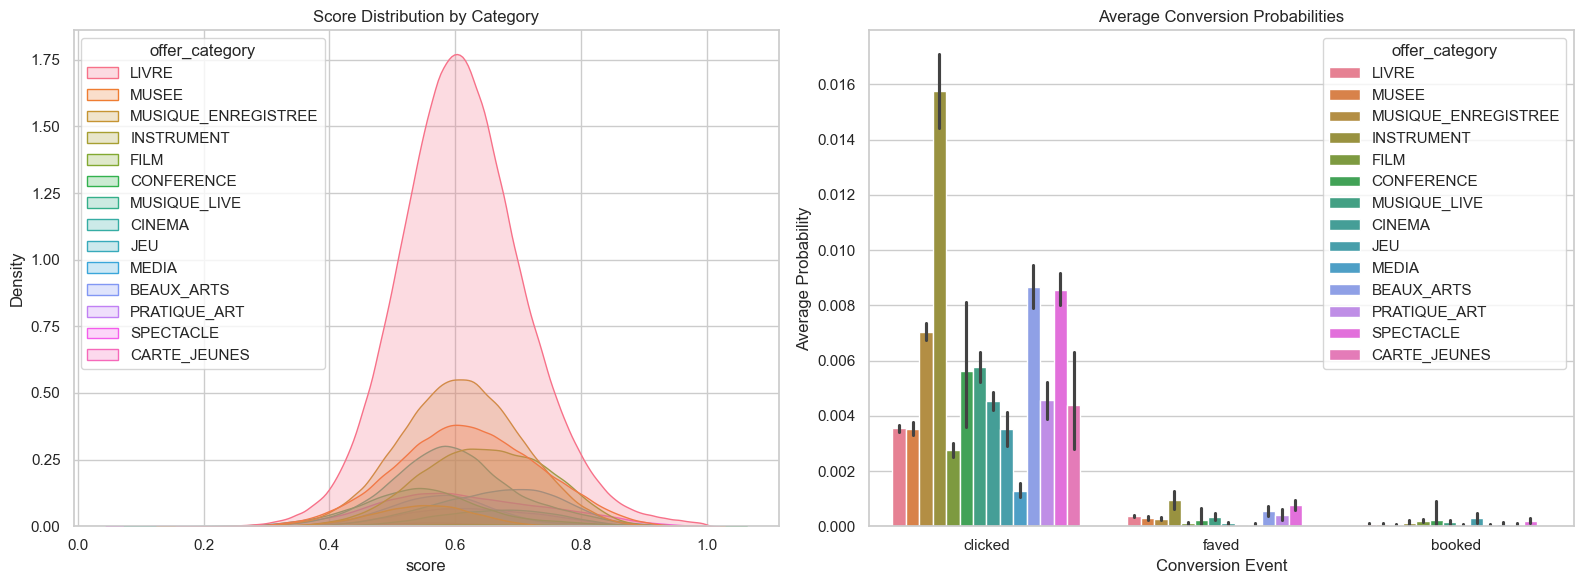

In [4]:
print(
    f"Total rows in dataset: {len(df_conv)}, total clicked: {df_conv['clicked'].sum()}, total faved: {df_conv['faved'].sum()}, total booked: {df_conv['booked'].sum()}"  # noqa: E501
)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.kdeplot(data=df_conv, x="score", hue="offer_category", fill=True, ax=axes[0])
axes[0].set_title("Score Distribution by Category")

melted = df_conv.melt(
    id_vars="offer_category", value_vars=["clicked", "faved", "booked"]
)
sns.barplot(data=melted, x="variable", y="value", hue="offer_category", ax=axes[1])
axes[1].set_title("Average Conversion Probabilities")
axes[1].set_xlabel("Conversion Event")
axes[1].set_ylabel("Average Probability")

plt.tight_layout()
plt.show()

### On veut qualifier un lien entre le score du Two Tower et les probabilités de conversion

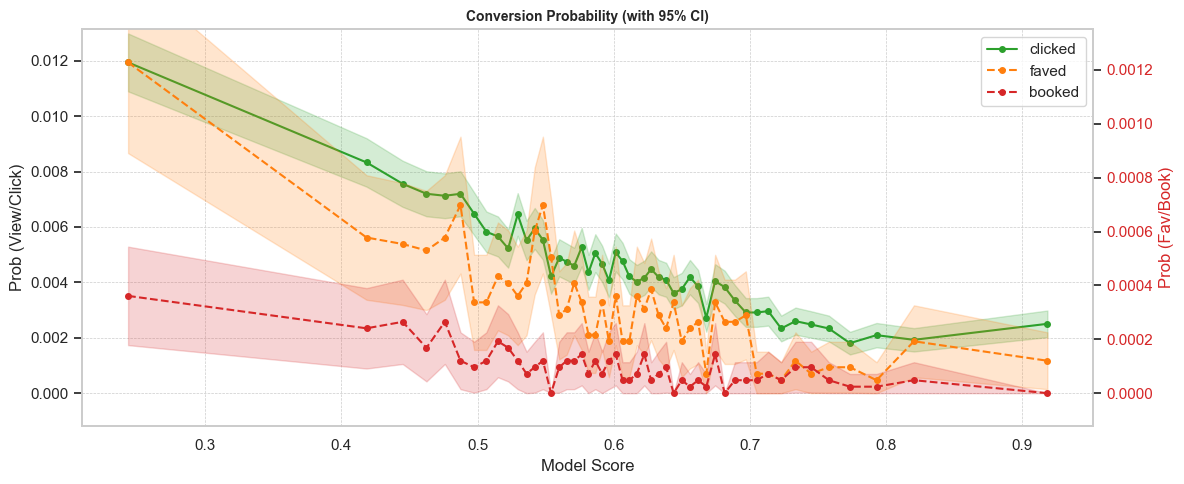

In [5]:
agg = (
    df_conv.groupby("score_bin", observed=False)[events]
    .agg(["mean", "sem"])
    .reset_index()
)

fig, axes = plt.subplots(figsize=(12, 5))

ax1 = axes
ax2 = ax1.twinx()

lineplot_conv_events(
    ax1,
    ax2,
    agg,
    events,
    title="Conversion Probability (with 95% CI)",
    CI_wrapper=True,
)

plt.tight_layout()
plt.show()

#### On observe des courbes qui semblent simples a approximer par des exponentielles decroissantes. Essayons.

### Pour obtenir les paramètre précis pour chaque type d'event, on fait appel à la fonction ```curve_fit``` de ```scipy```

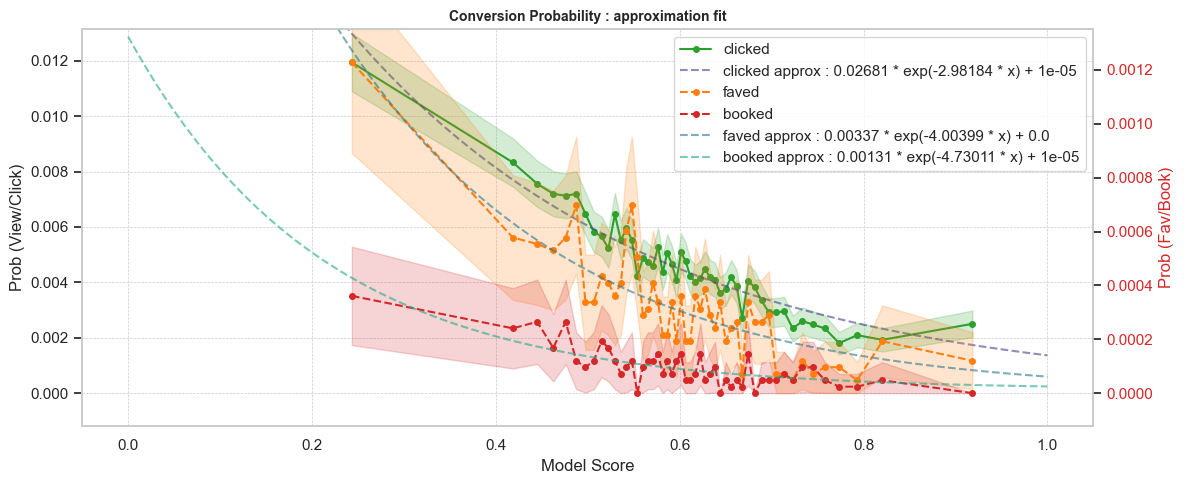

In [6]:
import numpy as np
from scipy.optimize import curve_fit


def exponential_approx(x, k, a, b):
    return k * np.exp(-a * x) + b


def weibull_decay(x, k=0.5, lam=1.0):
    return (k / lam) * (x / lam) ** (k - 1) * np.exp(-((x / lam) ** k))


agg = (
    df_conv.groupby("score_bin", observed=False)[events]
    .agg(["mean", "sem"])
    .reset_index()
)

fig, axes = plt.subplots(figsize=(12, 5))

ax1 = axes
ax2 = ax1.twinx()

lineplot_conv_events(
    ax1,
    ax2,
    agg,
    events,
    title="Conversion Probability : approximation fit",
    CI_wrapper=True,
)

params_map = {
    ax1: {"k": (ax1.get_ylim()[1] / 1.1), "a": 15, "b": 0.017, "color": "black"},
    ax2: {"k": (ax2.get_ylim()[1] / 1.1), "a": 15, "b": 0, "color": "blue"},
}
x = np.linspace(0, 1, 100)

# Convert score_bin to numeric values for curve_fit
score_bin_numeric = agg["score_bin"].astype(float).values
colors = sns.color_palette("viridis", 4)

event_params = {}

for event in events:
    params, covariance = curve_fit(
        exponential_approx,
        score_bin_numeric,
        agg[event]["mean"].values,
        p0=[ax2.get_ylim()[1] / 1.1, 5, 0],
        bounds=(0, np.inf),
    )

    ax = ax1 if event in ["viewed", "clicked"] else ax2
    p = params_map.get(ax)
    y = exponential_approx(x, params[0], params[1], params[2])
    k, a, b = np.round(params[0], 5), np.round(params[1], 5), np.round(params[2], 5)
    ax.plot(
        x,
        y,
        label=f"{event} approx : {k} * exp(-{a} * x) + {b}",
        color=colors[events.index(event)],
        linestyle="--",
        alpha=0.6,
    )
    event_params[event] = {"k": params[0], "a": params[1], "b": params[2]}

lines, labels = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="upper right")

plt.tight_layout()
plt.show()

## TT score distribution indicator

In [ ]:
score_distrib_query = """
SELECT user_id, offer_context.offer_item_score as score
FROM `passculture-data-prod.int_pcreco_prod.past_offer_context_sink`
WHERE event_date >= DATE_ADD(CURRENT_DATE('Europe/Paris'), INTERVAL - 1 week)
AND offer_context.offer_item_score <= 1
"""
score_df = runner.load_query_results(
    score_distrib_query, f"{DATA_DIR}/score_distrib.parquet"
)

In [8]:
print(
    f"Rows for user_id -1 (invalid): {len(score_df[score_df['user_id'] == '-1'])}, total rows: {len(score_df)}"  # noqa: E501
)
print(f"valid rows: {len(score_df[score_df['user_id'] != '-1'])}")

Rows for user_id -1 (invalid): 72761420, total rows: 99864768
valid rows: 27103348


Text(0.5, 1.0, 'Score Distribution')

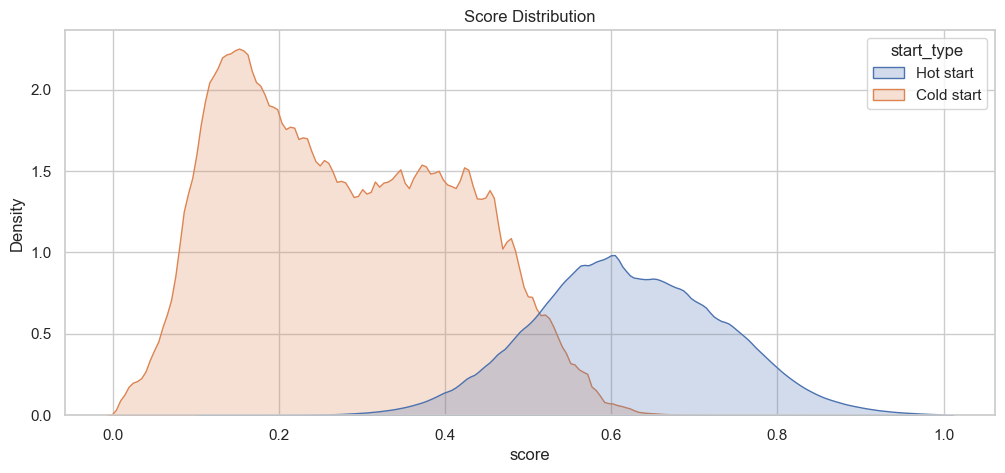

In [9]:
score_df["start_type"] = "Hot start"
score_df.loc[score_df["user_id"] == "-1", "start_type"] = "Cold start"
fig, ax = plt.subplots(figsize=(12, 5))
sns.kdeplot(data=score_df, x="score", hue="start_type", fill=True, ax=ax)
ax.set_title("Score Distribution")

# Autres viz

Les deux premières n'ont de sens que lorsqu'on s'interesse à plusieurs rangs, et au lien entre le rang et la conversion

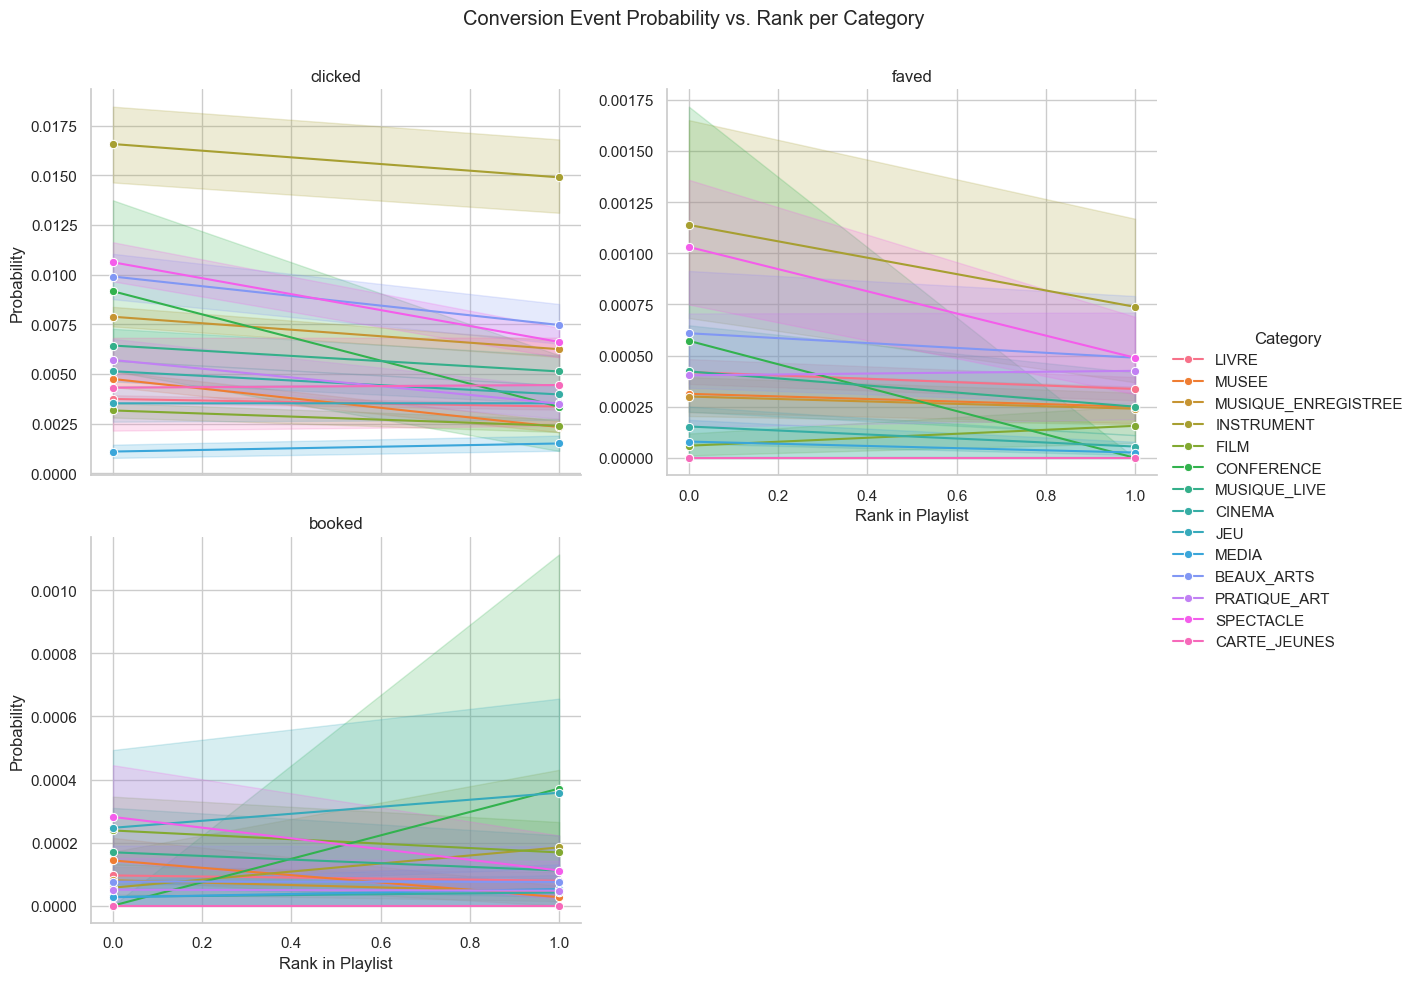

In [10]:
df_long = df_conv.melt(
    id_vars=["offer_category", "offer_reco_rank"],
    value_vars=events,
    var_name="event",
    value_name="is_converted",
)

sns.set_theme(style="whitegrid")
g = sns.FacetGrid(
    df_long,
    col="event",
    hue="offer_category",
    col_wrap=2,
    height=5,
    aspect=1.2,
    sharey=False,
)

g.map(sns.lineplot, "offer_reco_rank", "is_converted", marker="o")

g.set_axis_labels("Rank in Playlist", "Probability")
g.add_legend(title="Category")
g.set_titles("{col_name}")
plt.subplots_adjust(top=0.9)
g.figure.suptitle("Conversion Event Probability vs. Rank per Category")

plt.show()

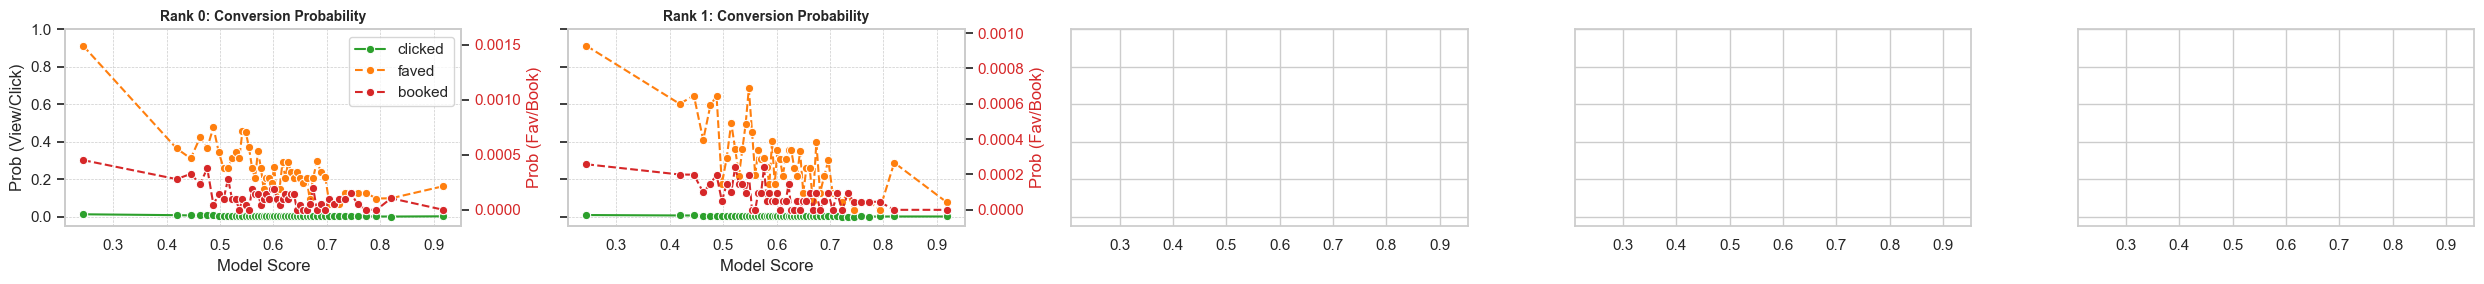

In [11]:
ranks = sorted(df_conv["offer_reco_rank"].unique())

cols = 5
rows = (len(ranks) + 1) // cols
fig, axes = plt.subplots(
    rows + 1, cols, figsize=(5 * cols, 4 * rows + 3), sharex=True, sharey=True
)
axes = axes.flatten()

for i, rank in enumerate(ranks):
    agg = (
        df_conv[df_conv["offer_reco_rank"] == rank]
        .groupby("score_bin", observed=False)[events]
        .mean()
        .reset_index()
    )

    ax1 = axes[i]
    ax2 = ax1.twinx()

    lineplot_conv_events(
        ax1, ax2, agg, events, title=f"Rank {rank}: Conversion Probability"
    )

    ax1.set_ylim(-0.05, 1)
    if i != 0:
        ax1.get_legend().remove()

plt.tight_layout()
plt.show()

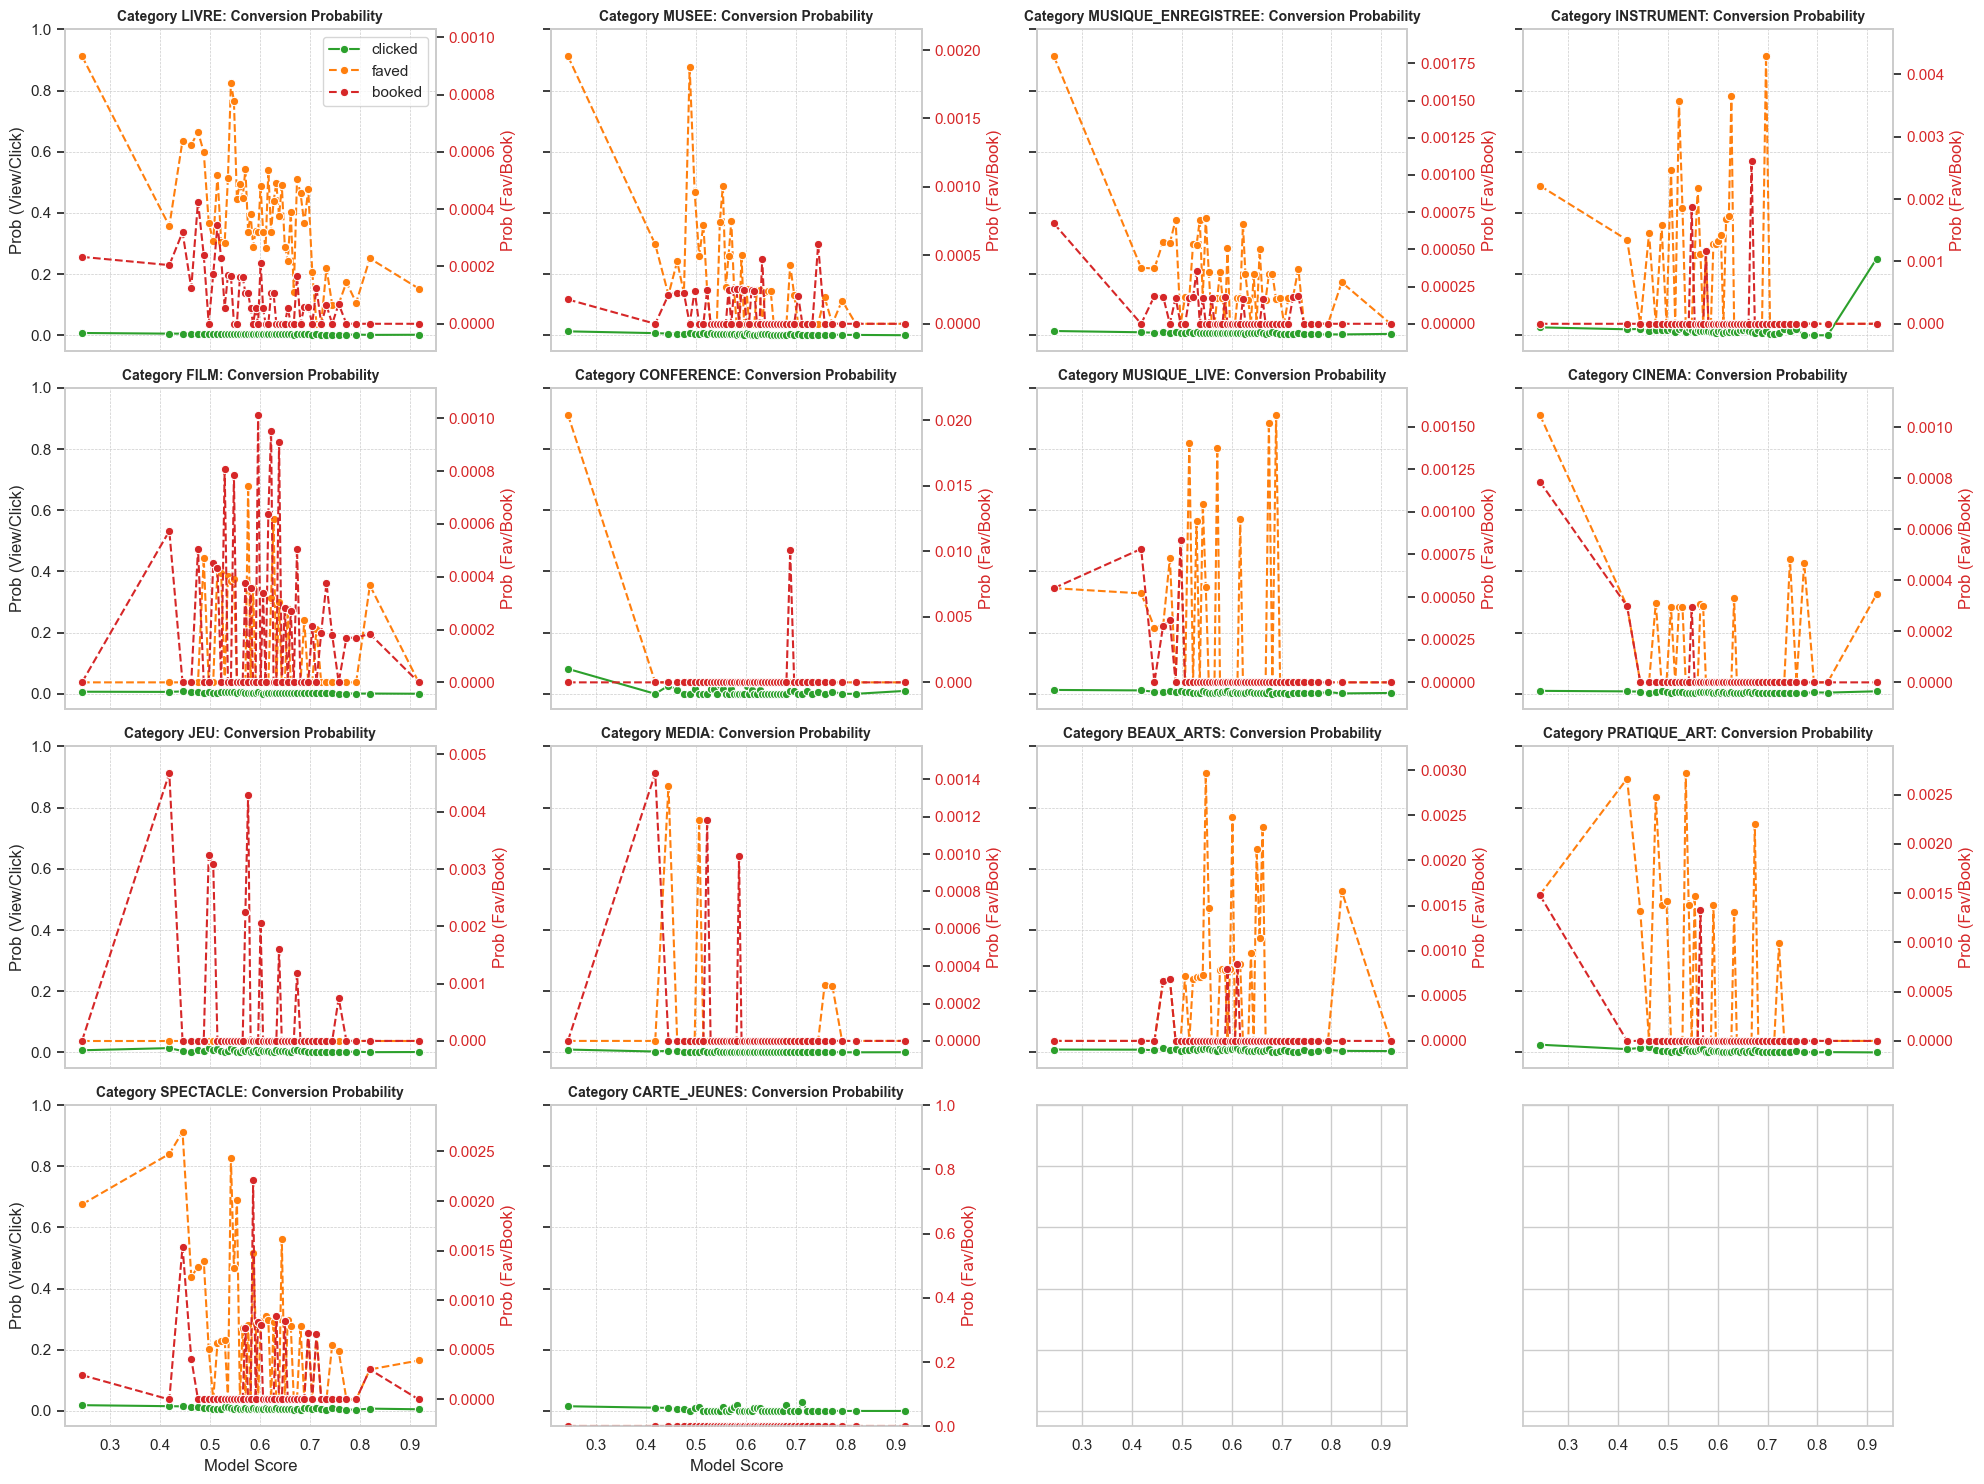

In [12]:
categories = df_conv["offer_category"].unique()

cols = 4
rows = (len(categories) + 1) // cols
_, axes = plt.subplots(
    rows + 1, cols, figsize=(5 * cols, 4 * rows + 3), sharex=True, sharey=True
)
axes = axes.flatten()

for i, cat in enumerate(categories):
    cat_data = df_conv[df_conv["offer_category"] == cat]

    agg = cat_data.groupby("score_bin", observed=False)[events].mean().reset_index()

    ax1 = axes[i]
    ax2 = ax1.twinx()

    lineplot_conv_events(
        ax1, ax2, agg, events, title=f"Category {cat}: Conversion Probability"
    )

    ax1.set_ylim(-0.05, 1)
    if i != 0:
        ax1.get_legend().remove()

plt.xlabel("Model Score (Quantile Mids)")
plt.tight_layout()
plt.show()